
PREDICTION BEFORE EXECUTION:
Original Bell State Circuit (|Phi+>):
- State: (|00> + |11>) / sqrt(2)
- Expected Outcomes: Approximately 50% '00' and 50% '11'.

Modified Circuit (Added X-gate to Qubit 0):
- State: (|01> + |10>) / sqrt(2)
- Expected Outcomes: Bit-flip on Qubit 0 changes the state to anti-correlated.
- Outcomes '01' and '10' will dominate (approx. 50% each).
- Outcomes '00' and '11' will no longer occur.


--- Original Bell-State Circuit ---
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

--- Modified Quantum Circuit ---
     ┌───┐     ┌───┐┌─┐
q_0: ┤ H ├──■──┤ X ├┤M├
     └───┘┌─┴─┐└┬─┬┘└╥┘
q_1: ─────┤ X ├─┤M├──╫─
          └───┘ └╥┘  ║ 
c: 2/════════════╩═══╩═
                 1   0 

MEASUREMENT RESULTS (100 Shots Each)
Original Circuit Counts: {'00': 49, '11': 51}
Modified Circuit Counts: {'10': 46, '01': 54}


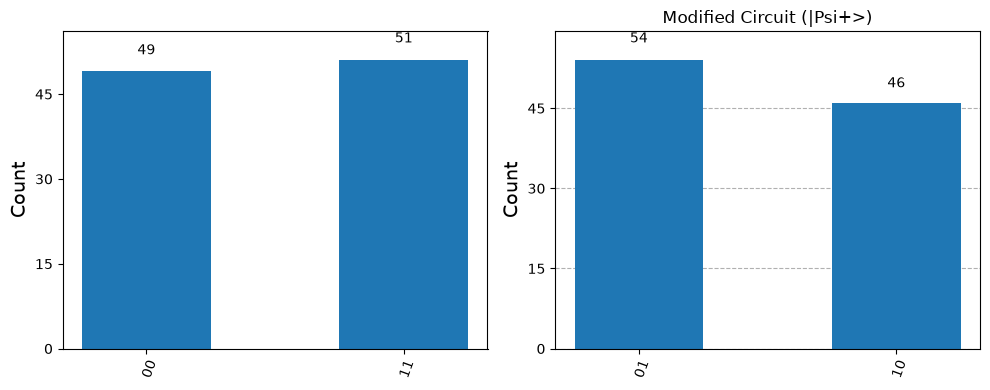


EXPLANATION OF THE OBSERVED CHANGE:
1. Original Circuit Behavior:
   - The H gate puts Qubit 0 into superposition, and the CNOT entangles 
     Qubit 1 with Qubit 0, forming the Bell state (|00> + |11>) / sqrt(2).
   - This causes both qubits to always yield identical measurement outcomes 
     ('00' or '11').

2. Effect of the Modification:
   - Adding an X gate (NOT gate) to Qubit 0 flips its state (0 -> 1 and 1 -> 0).
   - This transforms the entangled state into (|01> + |10>) / sqrt(2).
   - As a result, the measurement outcome relationship changes from 
     correlated ('00' and '11') to anti-correlated ('01' and '10').



In [1]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# ==========================================================
# 1. Prediction Before Execution
# ==========================================================
prediction_text = """
============================================================
PREDICTION BEFORE EXECUTION:
============================================================
Original Bell State Circuit (|Phi+>):
- State: (|00> + |11>) / sqrt(2)
- Expected Outcomes: Approximately 50% '00' and 50% '11'.

Modified Circuit (Added X-gate to Qubit 0):
- State: (|01> + |10>) / sqrt(2)
- Expected Outcomes: Bit-flip on Qubit 0 changes the state to anti-correlated.
- Outcomes '01' and '10' will dominate (approx. 50% each).
- Outcomes '00' and '11' will no longer occur.
============================================================
"""
print(prediction_text)

# ==========================================================
# 2. Create the Circuits
# ==========================================================
# Circuit A: Original Bell State (|Phi+>)
qc_original = QuantumCircuit(2, 2)
qc_original.h(0)         # Hadamard gate on qubit 0
qc_original.cx(0, 1)     # CNOT gate (control: 0, target: 1)
qc_original.measure([0, 1], [0, 1])

# Circuit B: Modified Circuit (Adding 1 gate: X gate on qubit 0)
qc_modified = QuantumCircuit(2, 2)
qc_modified.h(0)         # Hadamard gate
qc_modified.cx(0, 1)     # CNOT gate
qc_modified.x(0)         # MODIFICATION: Added X gate on qubit 0
qc_modified.measure([0, 1], [0, 1])

# Display Circuit Diagrams
print("\n--- Original Bell-State Circuit ---")
print(qc_original.draw(output='text'))

print("\n--- Modified Quantum Circuit ---")
print(qc_modified.draw(output='text'))

# ==========================================================
# 3. Execute both circuits for 100 shots
# ==========================================================
simulator = AerSimulator()

job_orig = simulator.run(qc_original, shots=100)
counts_orig = job_orig.result().get_counts()

job_mod = simulator.run(qc_modified, shots=100)
counts_mod = job_mod.result().get_counts()

# ==========================================================
# 4. Display Measurement Results
# ==========================================================
print("\n============================================================")
print("MEASUREMENT RESULTS (100 Shots Each)")
print("============================================================")
print(f"Original Circuit Counts: {counts_orig}")
print(f"Modified Circuit Counts: {counts_mod}")

# ==========================================================
# 5. Display Results using Histograms
# ==========================================================
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_histogram(counts_orig, ax=ax[0], title="Original Circuit (|Phi+>)")
plot_histogram(counts_mod, ax=ax[1], title="Modified Circuit (|Psi+>)")
plt.tight_layout()
plt.show()

# ==========================================================
# 6. Explanation of the Observed Change
# ==========================================================
explanation_text = """
============================================================
EXPLANATION OF THE OBSERVED CHANGE:
============================================================
1. Original Circuit Behavior:
   - The H gate puts Qubit 0 into superposition, and the CNOT entangles 
     Qubit 1 with Qubit 0, forming the Bell state (|00> + |11>) / sqrt(2).
   - This causes both qubits to always yield identical measurement outcomes 
     ('00' or '11').

2. Effect of the Modification:
   - Adding an X gate (NOT gate) to Qubit 0 flips its state (0 -> 1 and 1 -> 0).
   - This transforms the entangled state into (|01> + |10>) / sqrt(2).
   - As a result, the measurement outcome relationship changes from 
     correlated ('00' and '11') to anti-correlated ('01' and '10').
============================================================
"""
print(explanation_text)